# Spaceship Titanic Project

<!-- just for my own reference -->

## Algorithms Used

- Successful Transportation Prediction
    - Logistic Regression (Parametric)
    - Support Vector Machines
    - K-Nearest Neighbors (Non-Parametric)
    - Random Forest (Ensemble)
- Discovering groups of passangers with similar attributes
    - K-Means Clustering

## Dataset

The dataset used for this project is the "Spaceship Titanic" dataset available on Kaggle.
Link to the dataset: [SpaceShip Titanic](https://www.kaggle.com/competitions/spaceship-titanic/)

## Dataset Information

Required columns in the dataset:

- `PassengerId`: A unique Id for each passenger.
- `CryoSleep`: Indicates whether the passenger elected to be put into suspended chamber for the duration of the voyage.
- `Destination`: The planet the passenger will be debarking to.
- `Age`: The age of the passenger.
- `VIP`: Whether the passenger has paid for special VIP service during the voyage.
- `Transported`: Whether the passenger was transported to another dimension.
- `Cabin`: The cabin number where the passenger is staying.

In [7]:
# Importing libraries
import os
import kagglehub

import numpy as np
import pandas as pd

In [8]:
from google.colab import userdata
userdata.get('KAGGLE_API_TOKEN')

path = kagglehub.competition_download('spaceship-titanic')
print("\nPath to dataset files:", path)


Path to dataset files: /root/.cache/kagglehub/competitions/spaceship-titanic


### Data Wrangling
This section includes cleaning of the data in the following ways:

- Dropping irrelevant columns like `df_url`.
- Dropping null entries.
- Checking incorrect dtypes and converting to correct ones.
- Dropping entries with duplicate `title`.
- Dropping outliers from `tweet_num` as most entries have retweets < 500.

In [121]:
df = pd.read_csv(f"{path}/train.csv")
display(df.head())

df_test = pd.read_csv(f"{path}/test.csv")
display(df_test.head())

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


In [122]:
# Dropping irrelevant columns
df = df.drop(columns = ['Name'])

df_test = df_test.drop(columns = ['Name'])

In [123]:
# Handling null values
print("\nNull Entries: ")
print(df.isnull().sum())
print(df_test.isnull().sum())

df['CryoSleep'] = df['CryoSleep'].fillna(False)
df['VIP'] = df['VIP'].fillna(False)

df_test['CryoSleep'] = df_test['CryoSleep'].fillna(False)
df_test['VIP'] = df_test['VIP'].fillna(False)

print("\nAfter dropping null entries: ")
print(df.isnull().sum())
print(df_test.isnull().sum())


Null Entries: 
PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Transported       0
dtype: int64
PassengerId       0
HomePlanet       87
CryoSleep        93
Cabin           100
Destination      92
Age              91
VIP              93
RoomService      82
FoodCourt       106
ShoppingMall     98
Spa             101
VRDeck           80
dtype: int64

After dropping null entries: 
PassengerId       0
HomePlanet      201
CryoSleep         0
Cabin           199
Destination     182
Age             179
VIP               0
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Transported       0
dtype: int64
PassengerId       0
HomePlanet       87
CryoSleep         0
Cabin           100
Destination      92
Age              91
VIP               0
RoomService   

/tmp/ipykernel_3307/457885544.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['CryoSleep'] = df['CryoSleep'].fillna(False)
/tmp/ipykernel_3307/457885544.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['VIP'] = df['VIP'].fillna(False)
/tmp/ipykernel_3307/457885544.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_test['C

In [124]:
# Checking incorrect data types
print(f"Original dtypes:\n{df.dtypes}")
print(f"Original dtypes for test dataset:\n{df_test.dtypes}")

df = df.astype({
    'CryoSleep': 'int32',
    'VIP': 'int32',
    'Transported': 'int32'
})

df_test = df_test.astype({
    'CryoSleep': 'int32',
    'VIP': 'int32',
})

print(f"\nDtypes after modificatin:\n{df.dtypes}")
print(f"Dtypes after modificatin:\n{df_test.dtypes}")

Original dtypes:
PassengerId      object
HomePlanet       object
CryoSleep          bool
Cabin            object
Destination      object
Age             float64
VIP                bool
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Transported        bool
dtype: object
Original dtypes for test dataset:
PassengerId      object
HomePlanet       object
CryoSleep          bool
Cabin            object
Destination      object
Age             float64
VIP                bool
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
dtype: object

Dtypes after modificatin:
PassengerId      object
HomePlanet       object
CryoSleep         int32
Cabin            object
Destination      object
Age             float64
VIP               int32
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Transp

In [125]:
print("Final Dataset:")
display(df.sample(10))

print("\nFinal Test Dataset:")
display(df_test.sample(10))

Final Dataset:


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported
7449,7972_01,Europa,1,B/260/P,55 Cancri e,33.0,0,0.0,0.0,0.0,0.0,0.0,1
7617,8136_02,Europa,0,C/268/P,TRAPPIST-1e,60.0,0,0.0,5998.0,0.0,4794.0,8.0,0
3547,3811_01,Mars,1,F/786/P,TRAPPIST-1e,54.0,0,0.0,0.0,0.0,0.0,0.0,1
1613,1709_06,Mars,0,D/61/S,TRAPPIST-1e,15.0,0,1554.0,0.0,646.0,20.0,1241.0,0
2663,2856_01,Europa,0,C/108/S,55 Cancri e,38.0,0,0.0,896.0,0.0,NaN,4168.0,0
168,0192_03,Earth,0,G/29/P,TRAPPIST-1e,39.0,0,0.0,0.0,10.0,898.0,0.0,0
169,0193_01,Mars,1,F/41/P,TRAPPIST-1e,2.0,0,0.0,0.0,0.0,0.0,0.0,1
165,0190_01,Earth,1,G/32/S,55 Cancri e,11.0,0,0.0,0.0,0.0,0.0,0.0,0
8639,9220_01,Earth,0,G/1496/P,TRAPPIST-1e,25.0,0,2.0,45.0,45.0,0.0,815.0,0
2703,2893_01,Earth,0,G/470/P,55 Cancri e,27.0,0,688.0,307.0,779.0,0.0,19.0,0



Final Test Dataset:


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
4220,9155_02,Europa,0,C/304/P,TRAPPIST-1e,48.0,0,0.0,7.0,12.0,78.0,1779.0
4271,9266_01,Earth,0,F/1796/S,TRAPPIST-1e,40.0,0,0.0,865.0,0.0,3.0,0.0
3953,8593_01,Earth,0,F/1657/S,TRAPPIST-1e,41.0,0,2789.0,0.0,0.0,0.0,0.0
3529,7657_01,Earth,0,F/1463/S,PSO J318.5-22,24.0,0,12.0,158.0,0.0,0.0,1241.0
25,0055_01,Earth,0,G/5/P,TRAPPIST-1e,24.0,0,1784.0,8.0,18.0,18.0,0.0
2345,5098_01,Earth,0,F/976/S,TRAPPIST-1e,44.0,0,0.0,83.0,0.0,68.0,586.0
909,1894_01,Mars,1,F/379/P,TRAPPIST-1e,19.0,0,0.0,0.0,0.0,0.0,0.0
3307,7243_05,Earth,1,G/1180/S,PSO J318.5-22,5.0,0,0.0,0.0,0.0,0.0,0.0
3369,7369_01,Mars,0,F/1524/P,TRAPPIST-1e,31.0,0,953.0,0.0,20.0,382.0,556.0
808,1652_01,Earth,1,G/259/S,PSO J318.5-22,4.0,0,0.0,0.0,0.0,0.0,0.0


### Data Preprocessing
This section includes creating new columns from `PassengerId` and `Cabin`

In [126]:
# Extracting number of family members from the PassengerId colmn.
df['FamSize'] = df['PassengerId'].str.extract(r'_(\d+)')
df = df.astype({'FamSize': 'int32'})
df = df.drop('PassengerId', axis=1)

df_test['FamSize'] = df_test['PassengerId'].str.extract(r'_(\d+)')
df_test = df_test.astype({'FamSize': 'int32'})
df_test = df_test.drop('PassengerId', axis=1)

display(df.head())
display(df_test.head())

,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,FamSize
0,Europa,0,B/0/P,TRAPPIST-1e,39.0,0,0.0,0.0,0.0,0.0,0.0,0,1
1,Earth,0,F/0/S,TRAPPIST-1e,24.0,0,109.0,9.0,25.0,549.0,44.0,1,1
2,Europa,0,A/0/S,TRAPPIST-1e,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,1
3,Europa,0,A/0/S,TRAPPIST-1e,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,2
4,Earth,0,F/1/S,TRAPPIST-1e,16.0,0,303.0,70.0,151.0,565.0,2.0,1,1


,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,FamSize
0,Earth,1,G/3/S,TRAPPIST-1e,27.0,0,0.0,0.0,0.0,0.0,0.0,1
1,Earth,0,F/4/S,TRAPPIST-1e,19.0,0,0.0,9.0,0.0,2823.0,0.0,1
2,Europa,1,C/0/S,55 Cancri e,31.0,0,0.0,0.0,0.0,0.0,0.0,1
3,Europa,0,C/1/S,TRAPPIST-1e,38.0,0,0.0,6652.0,0.0,181.0,585.0,1
4,Earth,0,F/5/S,TRAPPIST-1e,20.0,0,10.0,0.0,635.0,0.0,0.0,1


In [127]:
# Extracting deck information from the Cabin colmn.
df['Cabin_Deck'] = df['Cabin'].str[0]
df['Cabin_Side'] = df['Cabin'].str[-1]
df = df.drop('Cabin', axis=1)

df_test['Cabin_Deck'] = df_test['Cabin'].str[0]
df_test['Cabin_Side'] = df_test['Cabin'].str[-1]
df_test = df_test.drop('Cabin', axis=1)

display(df.head())
display(df_test.head())

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,FamSize,Cabin_Deck,Cabin_Side
0,Europa,0,TRAPPIST-1e,39.0,0,0.0,0.0,0.0,0.0,0.0,0,1,B,P
1,Earth,0,TRAPPIST-1e,24.0,0,109.0,9.0,25.0,549.0,44.0,1,1,F,S
2,Europa,0,TRAPPIST-1e,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,1,A,S
3,Europa,0,TRAPPIST-1e,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,2,A,S
4,Earth,0,TRAPPIST-1e,16.0,0,303.0,70.0,151.0,565.0,2.0,1,1,F,S


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,FamSize,Cabin_Deck,Cabin_Side
0,Earth,1,TRAPPIST-1e,27.0,0,0.0,0.0,0.0,0.0,0.0,1,G,S
1,Earth,0,TRAPPIST-1e,19.0,0,0.0,9.0,0.0,2823.0,0.0,1,F,S
2,Europa,1,55 Cancri e,31.0,0,0.0,0.0,0.0,0.0,0.0,1,C,S
3,Europa,0,TRAPPIST-1e,38.0,0,0.0,6652.0,0.0,181.0,585.0,1,C,S
4,Earth,0,TRAPPIST-1e,20.0,0,10.0,0.0,635.0,0.0,0.0,1,F,S


In [128]:
# Merging spendings columns
df['Spendings'] = df['RoomService'] + df['FoodCourt'] + df['ShoppingMall'] + df['Spa'] + df['VRDeck']
df = df.drop(['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck'], axis=1)

df_test['Spendings'] = df_test['RoomService'] + df_test['FoodCourt'] + df_test['ShoppingMall'] + df_test['Spa'] + df_test['VRDeck']
df_test = df_test.drop(['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck'], axis=1)

df['Spendings'] = df['Spendings'].where(df['CryoSleep'] == False, 0)
df_test['Spendings'] = df_test['Spendings'].where(df_test['CryoSleep'] == False, 0)

display(df.head())
display(df_test.head())

,HomePlanet,CryoSleep,Destination,Age,VIP,Transported,FamSize,Cabin_Deck,Cabin_Side,Spendings
0,Europa,0,TRAPPIST-1e,39.0,0,0,1,B,P,0.0
1,Earth,0,TRAPPIST-1e,24.0,0,1,1,F,S,736.0
2,Europa,0,TRAPPIST-1e,58.0,1,0,1,A,S,10383.0
3,Europa,0,TRAPPIST-1e,33.0,0,0,2,A,S,5176.0
4,Earth,0,TRAPPIST-1e,16.0,0,1,1,F,S,1091.0


,HomePlanet,CryoSleep,Destination,Age,VIP,FamSize,Cabin_Deck,Cabin_Side,Spendings
0,Earth,1,TRAPPIST-1e,27.0,0,1,G,S,0.0
1,Earth,0,TRAPPIST-1e,19.0,0,1,F,S,2832.0
2,Europa,1,55 Cancri e,31.0,0,1,C,S,0.0
3,Europa,0,TRAPPIST-1e,38.0,0,1,C,S,7418.0
4,Earth,0,TRAPPIST-1e,20.0,0,1,F,S,645.0


In [129]:
# Export clean dataset
with open(f"/content/spaceship-titanic_clean.csv", 'w') as fp:
    df.to_csv(fp, index=False)

In [130]:
df.isnull().sum()

,0
HomePlanet,201
CryoSleep,0
Destination,182
Age,179
VIP,0
Transported,0
FamSize,0
Cabin_Deck,199
Cabin_Side,199
Spendings,561


### Exploratory Data Analysis
This section includes inspecting the details of the dataset and exploring the distribution of the data using graphs using `matplotlib` and `seaborn`
- Dataset Info
- Distribution of `real` using bar graph & pie chart
- Histogram of `tweet_num`
- WordCloud of Real and Fake df
- Correlation Analysis of `tweet_num` and `real`

In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HomePlanet   8492 non-null   object 
 1   CryoSleep    8693 non-null   int32  
 2   Destination  8511 non-null   object 
 3   Age          8514 non-null   float64
 4   VIP          8693 non-null   int32  
 5   Transported  8693 non-null   int32  
 6   FamSize      8693 non-null   int32  
 7   Cabin_Deck   8494 non-null   object 
 8   Cabin_Side   8494 non-null   object 
 9   Spendings    8132 non-null   float64
dtypes: float64(2), int32(4), object(4)
memory usage: 543.4+ KB


In [132]:
print(f'Dataset Shape:\n  Rows: {df.shape[0]}\n  Columns: {df.shape[1]}')

print(f'\nColumn Names: {df.columns.tolist()}')

print(f"\nNo. of people who couldn't be transported: {df[df['Transported'] == 0].value_counts().sum()}")
print(f"No. of people who were transported successfully: {df[df['Transported'] == 1].value_counts().sum()}")

Dataset Shape:
  Rows: 8693
  Columns: 10

Column Names: ['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'Transported', 'FamSize', 'Cabin_Deck', 'Cabin_Side', 'Spendings']

No. of people who couldn't be transported: 3587
No. of people who were transported successfully: 3838


In [133]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CryoSleep,8693.0,0.349362,0.476796,0.0,0.0,0.0,1.00,1.0
Age,8514.0,28.827930,14.489021,0.0,19.0,27.0,38.00,79.0
VIP,8693.0,0.022892,0.149568,0.0,0.0,0.0,0.00,1.0
Transported,8693.0,0.503624,0.500016,0.0,0.0,1.0,1.00,1.0
FamSize,8693.0,1.517773,1.054241,1.0,1.0,1.0,2.00,8.0
Spendings,8132.0,1421.252213,2800.039209,0.0,0.0,705.0,1402.25,35987.0


In [134]:
# Importing libraries
import matplotlib.pyplot as plt
import seaborn as sns

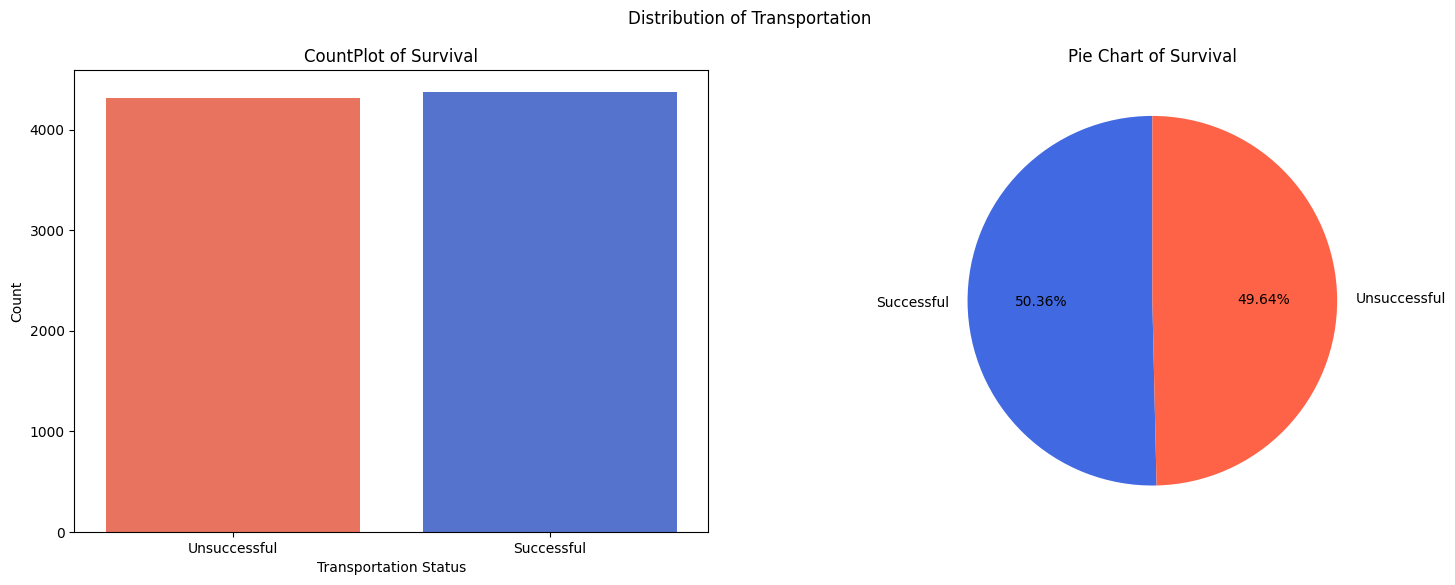


No. of people who couldn't be transported: 3587
No. of people who were transported successfully: 3838


In [135]:
# Distribution of Transportation
fig, ax = plt.subplots(1,2,figsize=(18,6))

sns.countplot(data=df, x='Transported', hue='Transported', palette=['tomato','royalblue'], legend=False, ax=ax[0])
ax[0].set_xticks([0,1],['Unsuccessful','Successful'])
ax[0].set_xlabel('Transportation Status')
ax[0].set_ylabel('Count')
ax[0].set_title('CountPlot of Survival')

ax[1].pie(df['Transported'].value_counts(), labels=['Successful', 'Unsuccessful'], startangle=90, autopct='%1.2f%%', colors=['royalblue','tomato'])
ax[1].set_title('Pie Chart of Survival')

fig.suptitle('Distribution of Transportation')
plt.show()
print(f"\nNo. of people who couldn't be transported: {df[df['Transported'] == 0].value_counts().sum()}")
print(f"No. of people who were transported successfully: {df[df['Transported'] == 1].value_counts().sum()}")

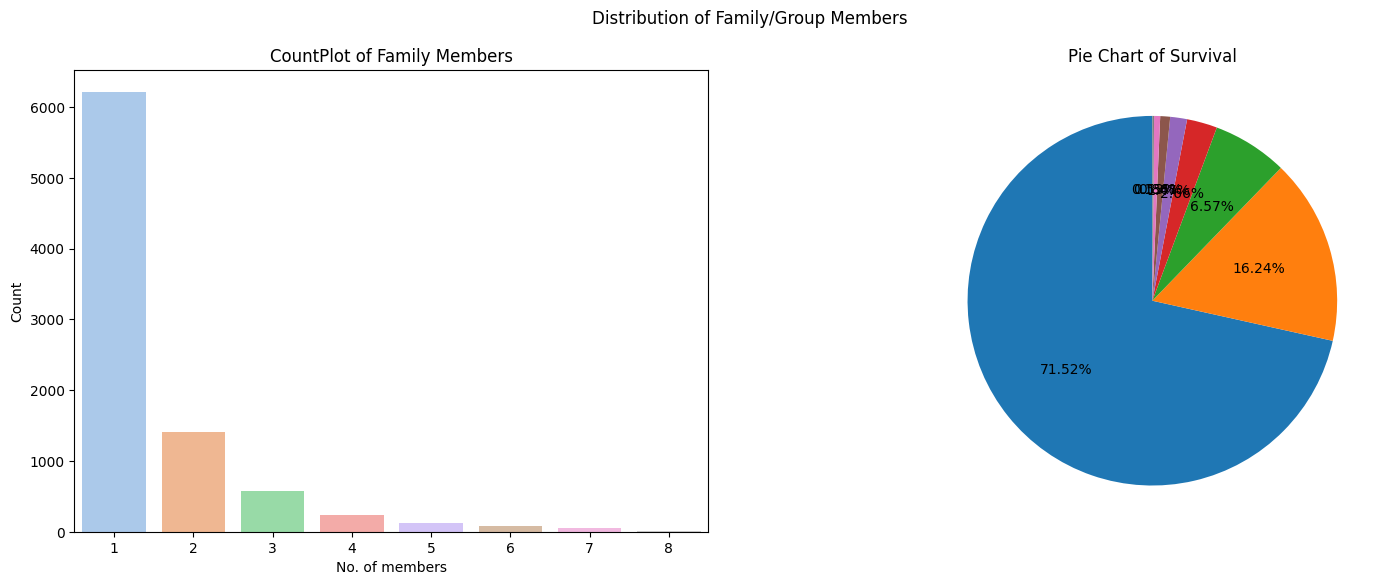

In [136]:
# Distribution of Family/Group Members
fig, ax = plt.subplots(1,2,figsize=(18,6))

sns.countplot(data=df, x='FamSize', hue='FamSize', palette='pastel', legend=False, ax=ax[0])
ax[0].set_xlabel('No. of members')
ax[0].set_ylabel('Count')
ax[0].set_title('CountPlot of Family Members')

ax[1].pie(df['FamSize'].value_counts(), startangle=90, autopct='%1.2f%%')
ax[1].set_title('Pie Chart of Survival')

fig.suptitle('Distribution of Family/Group Members')
plt.show()

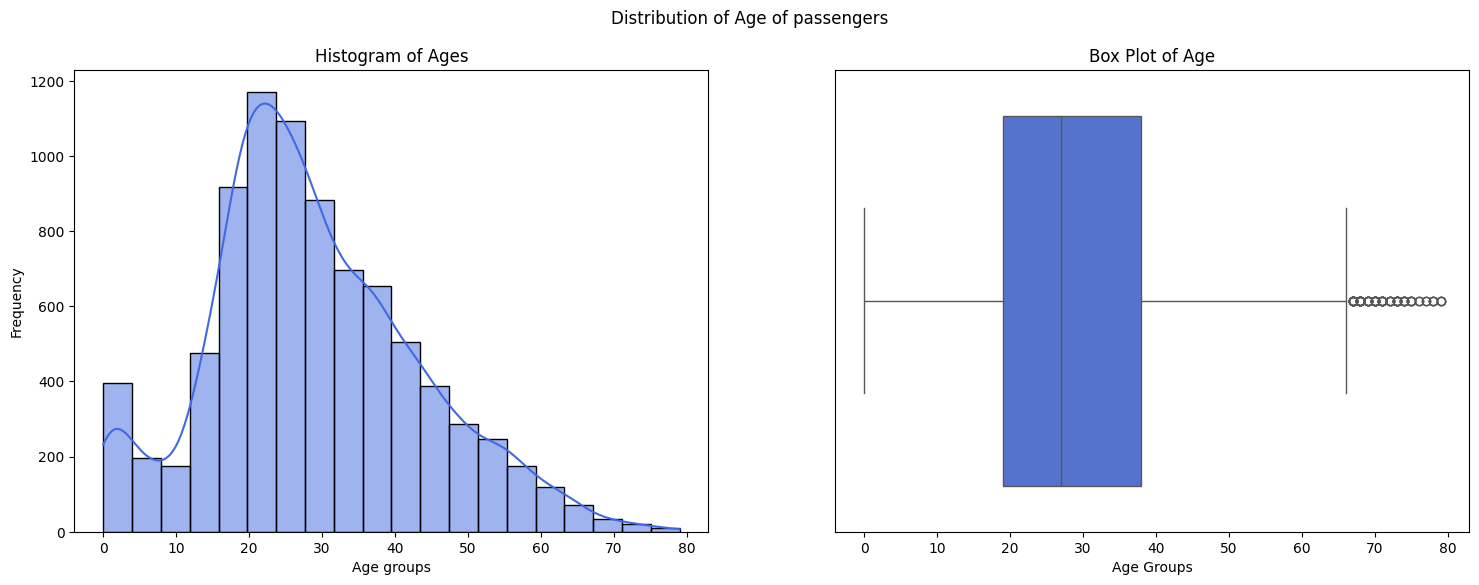

In [137]:
# Distribution of Age
fig, ax = plt.subplots(1,2,figsize=(18,6))

sns.histplot(data=df, x='Age', kde=True, bins=20, color='royalblue', ax=ax[0])
ax[0].set_xlabel('Age groups')
ax[0].set_ylabel('Frequency')
ax[0].set_title('Histogram of Ages')

sns.boxplot(data=df, x='Age', color='royalblue', ax=ax[1])
ax[1].set_title('Box Plot of Age')
ax[1].set_xlabel('Age Groups')
ax[1].set_yticks([])

fig.suptitle('Distribution of Age of passengers')
plt.show()

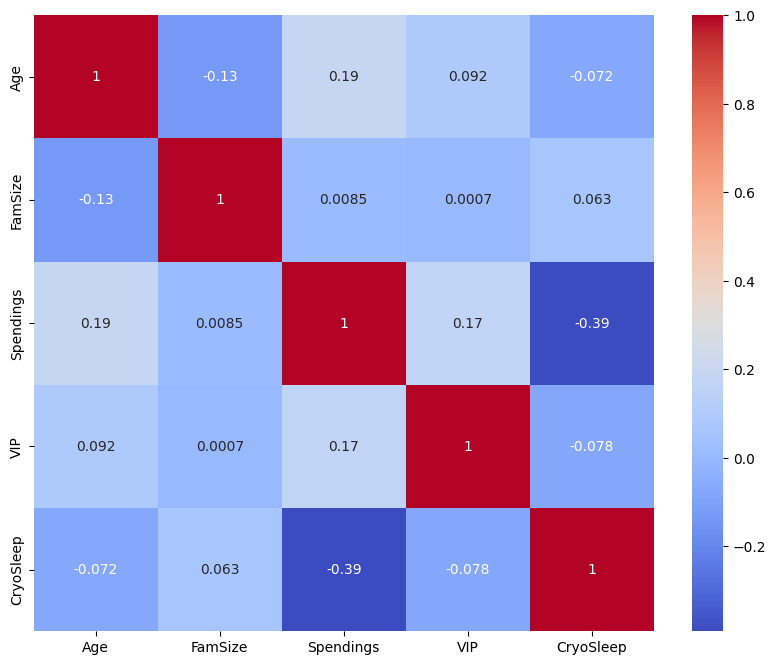

In [138]:
# Correlation Analysis of tweet_num and real column
plt.figure(figsize=(10, 8))
corr = df[['Age','FamSize', 'Spendings', 'VIP', 'CryoSleep']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

### Pipeline and Train Preparation
This section includes:
- Splitting train and test data from the cleaned dataset
- Creating pipelines to automate the transformation of:
  - categorical data (`source_domain`) using `OneHotEncoder`
  - numerical data (`tweet_num`) using `StandardScaler`
  - textual data (`title`) using `TfidfVectorizer`
- And feeding the transformers to the `ColumnTransformer` (pipeline)

In [139]:
# Importing libraries
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

In [140]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HomePlanet   8492 non-null   object 
 1   CryoSleep    8693 non-null   int32  
 2   Destination  8511 non-null   object 
 3   Age          8514 non-null   float64
 4   VIP          8693 non-null   int32  
 5   Transported  8693 non-null   int32  
 6   FamSize      8693 non-null   int32  
 7   Cabin_Deck   8494 non-null   object 
 8   Cabin_Side   8494 non-null   object 
 9   Spendings    8132 non-null   float64
dtypes: float64(2), int32(4), object(4)
memory usage: 543.4+ KB


In [141]:
X = df[['Age','CryoSleep','VIP','FamSize','Cabin_Deck', 'Cabin_Side', 'HomePlanet', 'Destination', 'Spendings']]
y = df['Transported']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
display(X_train.head())
display(y_train.head())

,Age,CryoSleep,VIP,FamSize,Cabin_Deck,Cabin_Side,HomePlanet,Destination,Spendings
3600,0.0,0,0,4,G,S,Earth,TRAPPIST-1e,0.0
1262,17.0,1,0,1,G,S,Earth,TRAPPIST-1e,0.0
8612,35.0,0,0,1,G,S,Earth,PSO J318.5-22,0.0
5075,26.0,1,0,1,D,S,Europa,55 Cancri e,0.0
4758,13.0,0,0,1,G,P,Earth,TRAPPIST-1e,5208.0


,Transported
3600,1
1262,1
8612,0
5075,1
4758,0


In [144]:
bool_features = ['CryoSleep', 'VIP']
cat_features = ['Cabin_Deck', 'Cabin_Side', 'HomePlanet', 'Destination']
num_features = ['Age', 'FamSize', 'Spendings']

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01, sparse_output=False))
])

num_transformer = Pipeline(steps=[
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('bool', 'passthrough', bool_features),
    ('cat', cat_transformer, cat_features),
    ('num', num_transformer, num_features)
])

### Model Training and Evaluation
This section includes training of four models:
- `Logistic Regression`:
  - Max Iterations: 1000
- `K-Nearest Neighbour`:
  - Nearest Neighbour (`k`): 5
- `Random Forest`:
  - No of Estimators (trees): 50
- `Feed-Forward Neural Network`:
  - Epochs: 60
  - Batch Size: 24

The models are evaluated based on the following metrics:
- `Accuracy`
- `Precision`
- `Recall`
- `F1 Score`
- `Train Loss` (FNN)

All the metrics of each models are then compared at the end of the trainign.

In [145]:
# Importing libraries
from sklearn import set_config
set_config(display='diagram')

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [146]:
eval_table = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

#### Logistic Regression

In [155]:
lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=100))
])

lr.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('bool', 'passthrough',
                                                  ['CryoSleep', 'VIP']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=0.01,
                                                                                 sparse_output=False))]),
                                                  ['Cabin_Deck', 'Cabin_Side',
                                                   'HomePlanet',
                                                   'Destination']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   KNNImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'FamSize',
                                                   'Spendings'])])),
                ('classifier', LogisticRegression())])

In [156]:
# Evaluation of model performance
print("Evaluation of Logistic Regression:")
y_pred_lr = lr.predict(X_val)

accuracy_lr = accuracy_score(y_val, y_pred_lr)
precision_lr = precision_score(y_val, y_pred_lr, zero_division=0)
recall_lr = recall_score(y_val, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_val, y_pred_lr, zero_division=0)

print(f"Accuracy: {accuracy_lr:.5f} ({accuracy_lr * 100:.2f}%)")
print(f"\nClassification Report: \n{classification_report(y_val, y_pred_lr, zero_division=0)}")

Evaluation of Logistic Regression:
Accuracy: 0.72283 (72.28%)

Classification Report: 
              precision    recall  f1-score   support

           0       0.69      0.81      0.74       863
           1       0.78      0.63      0.70       876

    accuracy                           0.72      1739
   macro avg       0.73      0.72      0.72      1739
weighted avg       0.73      0.72      0.72      1739



In [157]:
lr_eval = pd.DataFrame({
    'Model': ['Logistic Regression'],
    'Accuracy': [f'{accuracy_lr * 100:.2f}%'],
    'Precision': [f'{precision_lr * 100:.2f}%'],
    'Recall': [f'{recall_lr * 100:.2f}%'],
    'F1 Score': [f'{f1_lr * 100:.2f}%']
})
display(lr_eval)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,72.28%,77.59%,63.24%,69.69%


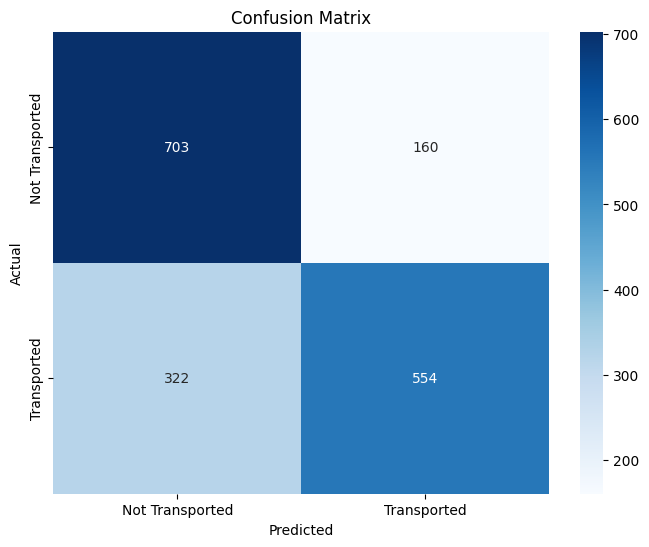

In [158]:
# Confusion matrix representation
cm = confusion_matrix(y_val, y_pred_lr)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Transported', 'Transported'], yticklabels=['Not Transported', 'Transported'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#### K-Nearest Neighbours

In [159]:
knn = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=3))
])

knn.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('bool', 'passthrough',
                                                  ['CryoSleep', 'VIP']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=0.01,
                                                                                 sparse_output=False))]),
                                                  ['Cabin_Deck', 'Cabin_Side',
                                                   'HomePlanet',
                                                   'Destination']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   KNNImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'FamSize',
                                                   'Spendings'])])),
                ('classifier', KNeighborsClassifier(n_neighbors=3))])

In [160]:
# Evaluation of model performance
print("Evaluation of K-Nearest Neighbours:")
print("[k set to 3]")
y_pred_knn = knn.predict(X_val)

accuracy_knn = accuracy_score(y_val, y_pred_knn)
precision_knn = precision_score(y_val, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_val, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_val, y_pred_knn, zero_division=0)

print(f"Accuracy: {accuracy_knn:.5f} ({accuracy_knn * 100:.2f}%)")
print(f"\nClassification Report: \n{classification_report(y_val, y_pred_knn, zero_division=0)}")

Evaluation of K-Nearest Neighbours:
[k set to 3]
Accuracy: 0.68373 (68.37%)

Classification Report: 
              precision    recall  f1-score   support

           0       0.67      0.72      0.69       863
           1       0.70      0.64      0.67       876

    accuracy                           0.68      1739
   macro avg       0.69      0.68      0.68      1739
weighted avg       0.69      0.68      0.68      1739



In [161]:
knn_eval = pd.DataFrame({
    'Model': ['K-Nearest Neighbours'],
    'Accuracy': [f'{accuracy_knn * 100:.2f}%'],
    'Precision': [f'{precision_knn * 100:.2f}%'],
    'Recall': [f'{recall_knn * 100:.2f}%'],
    'F1 Score': [f'{f1_knn * 100:.2f}%']
})
display(knn_eval)

,Model,Accuracy,Precision,Recall,F1 Score
0,K-Nearest Neighbours,68.37%,70.27%,64.50%,67.26%


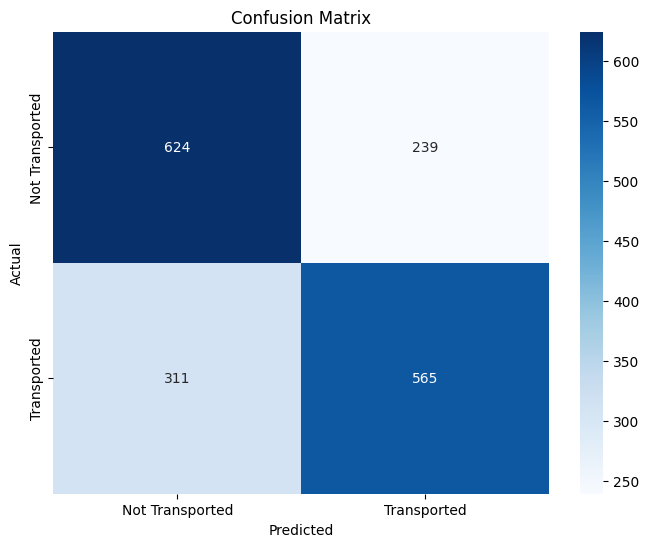

In [162]:
# Confusion matrix representation
cm = confusion_matrix(y_val, y_pred_knn)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Transported', 'Transported'], yticklabels=['Not Transported', 'Transported'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#### Random Forest

In [163]:
rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=50, random_state=42))
])

rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('bool', 'passthrough',
                                                  ['CryoSleep', 'VIP']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=0.01,
                                                                                 sparse_output=False))]),
                                                  ['Cabin_Deck', 'Cabin_Side',
                                                   'HomePlanet',
                                                   'Destination']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   KNNImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'FamSize',
                                                   'Spendings'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=50, random_state=42))])

In [164]:
# Evaluation of model performance
print("Evaluation of Random Forest:")
y_pred_rf = rf.predict(X_val)

accuracy_rf = accuracy_score(y_val, y_pred_rf)
precision_rf = precision_score(y_val, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_val, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_val, y_pred_rf, zero_division=0)

print(f"Accuracy: {accuracy_rf:.5f} ({accuracy_rf * 100:.2f}%)")
print(f"\nClassification Report: \n{classification_report(y_val, y_pred_rf, zero_division=0)}")

Evaluation of Random Forest:
Accuracy: 0.70960 (70.96%)

Classification Report: 
              precision    recall  f1-score   support

           0       0.69      0.75      0.72       863
           1       0.73      0.67      0.70       876

    accuracy                           0.71      1739
   macro avg       0.71      0.71      0.71      1739
weighted avg       0.71      0.71      0.71      1739



In [165]:
rf_eval = pd.DataFrame({
    'Model': ['Random Forest'],
    'Accuracy': [f'{accuracy_rf * 100:.2f}%'],
    'Precision': [f'{precision_rf * 100:.2f}%'],
    'Recall': [f'{recall_rf * 100:.2f}%'],
    'F1 Score': [f'{f1_rf * 100:.2f}%']
})
display(rf_eval)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,70.96%,73.22%,66.78%,69.85%


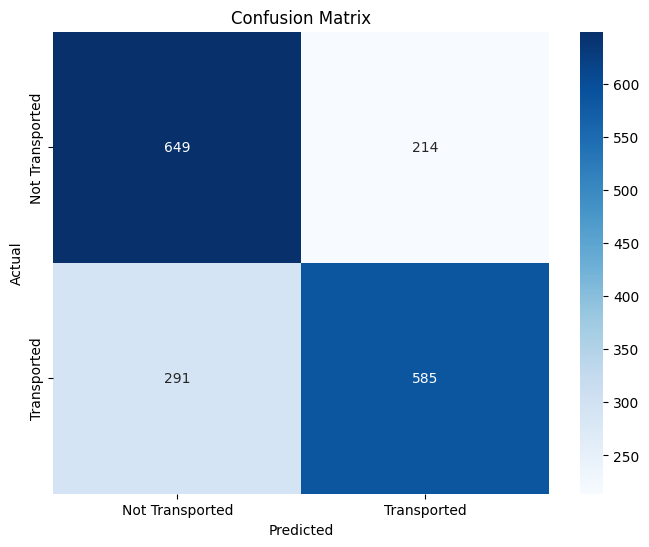

In [166]:
# Confusion matrix representation
cm = confusion_matrix(y_val, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Transported', 'Transported'], yticklabels=['Not Transported', 'Transported'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#### Feedforward Neural Network

In [167]:
set_config(display='text')

# Preprocess the data manually for the Keras model since sklearn.Pipeline isn't compatible with scikeras
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

early_stopping = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

fnn = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

fnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = fnn.fit(X_train_processed, y_train, epochs=20, batch_size=64, validation_data=(X_val_processed, y_val), callbacks=[early_stopping])

Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6432 - loss: 0.6294 - val_accuracy: 0.7257 - val_loss: 0.5547
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7189 - loss: 0.5604 - val_accuracy: 0.7297 - val_loss: 0.5300
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7295 - loss: 0.5444 - val_accuracy: 0.7343 - val_loss: 0.5213
Epoch 4/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7308 - loss: 0.5352 - val_accuracy: 0.7372 - val_loss: 0.5150
Epoch 5/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7305 - loss: 0.5298 - val_accuracy: 0.7332 - val_loss: 0.5113
Epoch 6/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7381 - loss: 0.5252 - val_accuracy: 0.7389 - val_loss: 0.5103
Epoch 7/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7394 - loss: 0.5241 - val_accuracy: 0.7372 - val_loss: 0.5079
Epoch 8/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7420 - loss: 0.5230 - val_accuracy: 0.

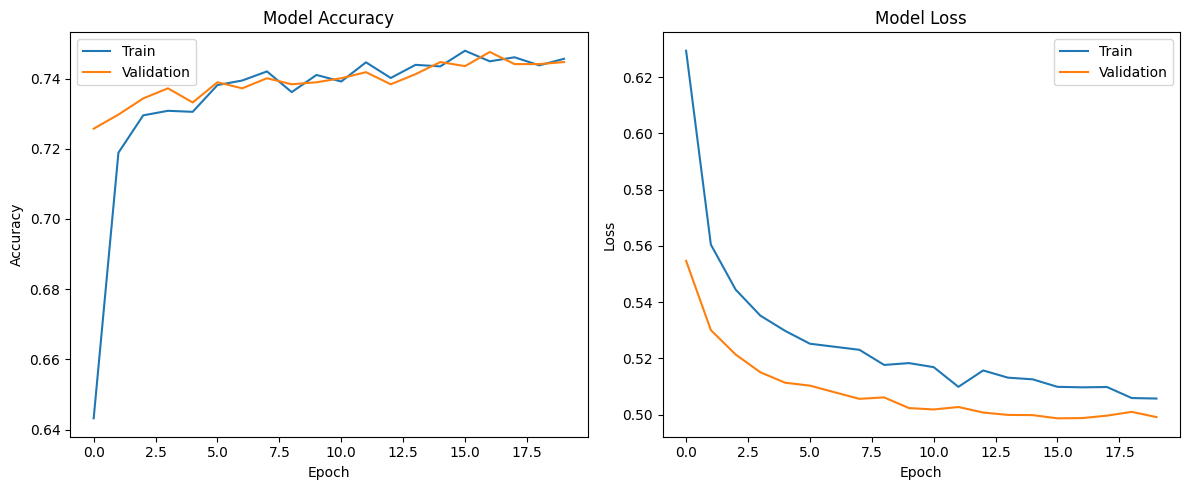

In [172]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])

plt.tight_layout()
plt.show()

In [173]:
# Evaluation of model performance
print("Evaluation of Feed-Forward Neural Network:")

# X_val_processed was created in the training cell for FNN
y_pred_fnn = (fnn.predict(X_val_processed) > 0.5).astype("int32")
loss_fnn, accuracy_fnn = fnn.evaluate(X_val_processed, y_val, verbose=0)
precision_fnn = precision_score(y_val, y_pred_fnn, zero_division=0)
recall_fnn = recall_score(y_val, y_pred_fnn, zero_division=0)
f1_fnn = f1_score(y_val, y_pred_fnn, zero_division=0)

print(f"Test Loss: {loss_fnn:.5f}")
print(f"Accuracy Score: {accuracy_fnn:.5f} ({accuracy_fnn * 100:.2f}%)")
print(f"\nClassification Report: \n{classification_report(y_val, y_pred_fnn, zero_division=0)}")

Evaluation of Feed-Forward Neural Network:
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 978us/step
Test Loss: 0.49864
Accuracy Score: 0.74353 (74.35%)

Classification Report: 
              precision    recall  f1-score   support

           0       0.70      0.86      0.77       863
           1       0.82      0.63      0.71       876

    accuracy                           0.74      1739
   macro avg       0.76      0.74      0.74      1739
weighted avg       0.76      0.74      0.74      1739



In [174]:
fnn_eval = pd.DataFrame({
    'Model': ['Feed-Forward Neural Network'],
    'Accuracy': [f'{accuracy_fnn * 100:.2f}%'],
    'Precision': [f'{precision_fnn * 100:.2f}%'],
    'Recall': [f'{recall_fnn * 100:.2f}%'],
    'F1 Score': [f'{f1_fnn * 100:.2f}%']
})
display(fnn_eval)

,Model,Accuracy,Precision,Recall,F1 Score
0,Feed-Forward Neural Network,74.35%,81.80%,63.13%,71.26%


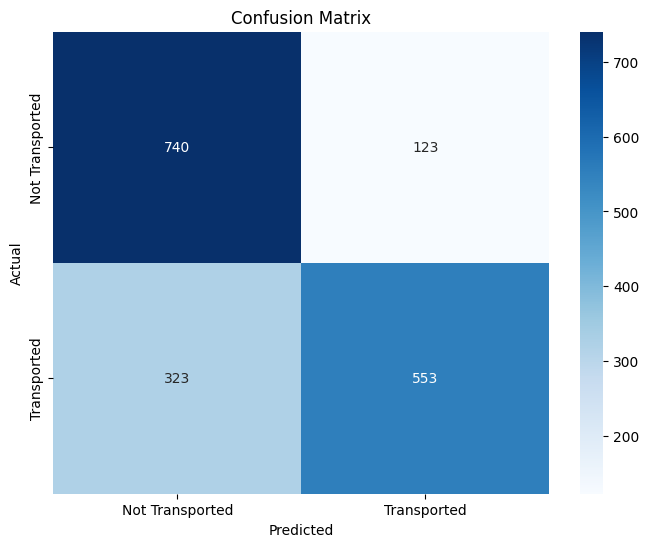

In [175]:
# Confusion matrix representation
cm = confusion_matrix(y_val, y_pred_fnn)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Transported', 'Transported'], yticklabels=['Not Transported', 'Transported'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Comparision of Model Performance

In [176]:
final_eval_table = pd.concat([eval_table,lr_eval,knn_eval,rf_eval,fnn_eval], axis='rows') # the code runs fine but dunno why it shows this error
final_eval_table.reset_index(drop=True, inplace=True)

print("The comparision of performance of all four models:")
display(final_eval_table)

The comparision of performance of all four models:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,72.28%,77.59%,63.24%,69.69%
1,K-Nearest Neighbours,68.37%,70.27%,64.50%,67.26%
2,Random Forest,70.96%,73.22%,66.78%,69.85%
3,Feed-Forward Neural Network,74.35%,81.80%,63.13%,71.26%
